# Guía de laboratorio 07 — Primalidad, grupos y algoritmos probabilísticos
**UNSAAC · Algoritmos Avanzados · 2026-II · Grupo 5**

**Integrantes:** Choquenaira Quispe, Noe Franklin (133962); Porroa Sivana, Yeni Ruth (120893); Quispe Rimachi, Romario (164257); Yaranga Achahui, Aldo (103179).

Ejecute **todas las celdas, desde el inicio**, en Google Colab o Jupyter con Python 3.11+. El cuaderno contiene código, pruebas, resultados y gráficos. No requiere archivos del repositorio: los módulos se crean en un directorio temporal de la sesión, no junto a este `.ipynb`. La celda inicial instala `matplotlib` y `pandas` solo si faltan.

## Preparación del entorno y fundamentos (guía, secciones 2–6)
Se usan `random.Random` y semillas fijas únicamente para reproducir experimentos. La generación sin semilla utiliza `secrets.SystemRandom`; una prueba superada no certifica primalidad de enteros grandes. Una base que rechaza en Fermat o Miller–Rabin prueba composición. La cota $4^{-r}$ supone un compuesto impar y $r$ bases independientes uniformes. La división de prueba es determinista pero necesita hasta $O(2^{L/2})$ divisiones para entradas de $L$ bits.

In [1]:
import importlib.util, os, platform, subprocess, sys, tempfile
from pathlib import Path
if sys.version_info < (3, 11):
    raise RuntimeError('La Guía 07 requiere Python 3.11 o posterior. Cambie el kernel.')
missing = [p for p in ('matplotlib', 'pandas') if importlib.util.find_spec(p) is None]
if missing:
    print('Instalando dependencias faltantes:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import matplotlib, pandas
# Los archivos de la ejecución no modifican la carpeta del cuaderno.
# Al repetir 'Ejecutar todas', conservamos la sesión previa hasta cerrar el kernel.
if 'session' in globals():
    session_history = globals().get('session_history', [])
    session_history.append(session)
    sys.path = [p for p in sys.path if p != str(WORK)]
    for name in ('primality', 'case_generator', 'ejercicios_resueltos',
                 'test_primality', 'experiments', 'verify_results'):
        sys.modules.pop(name, None)
session = tempfile.TemporaryDirectory(prefix='lab07_')
WORK = Path(session.name)
os.chdir(WORK)
sys.path.insert(0, str(WORK))
print('Entorno listo:', platform.python_version(), '| matplotlib', matplotlib.__version__, '| pandas', pandas.__version__)

Entorno listo: 3.12.8 | matplotlib 3.11.1 | pandas 3.0.6


## 8. Ejercicios resueltos — biblioteca compartida
Primero se definen las funciones usadas en los tres casos de la guía. Cada celda agrega una parte a `primality.py`; no se necesita subir ningún módulo. Las funciones se comprueban por separado más abajo.

### 8.1 División de prueba y Fermat
La división llega hasta `isqrt(n)`; Fermat usa bases válidas y comprueba coprimalidad.

In [2]:
%%writefile primality.py
"""Pruebas de primalidad y generación de probables primos (Guía 07, UNSAAC).

Una ronda de Miller--Rabin devuelve (pasa, detalle). El detalle incluye n, a,
s, d y, si trace=True, todos los residuos examinados. ``pasa`` NO certifica
primalidad; ``False`` sí certifica composición para n impar >= 5.

La fuente por defecto es secrets.SystemRandom; inyectar random.Random solo sirve
para ensayos reproducibles, nunca para generar claves criptográficas.
"""

import secrets
from math import gcd, isqrt

__all__ = [
    "trial_division", "trial_division_with_count", "fermat_round", "fermat_test",
    "decompose", "miller_rabin_round", "primality_report", "is_probable_prime",
    "generate_candidate", "generate_probable_prime", "classify_bases",
]


def _integer(*values):
    for value in values:
        if type(value) is not int:
            raise TypeError("Se esperaba un entero, no bool ni otro tipo")


def _primes_up_to(limit):
    sieve = bytearray(b"\x01") * (limit + 1)
    sieve[0:2] = b"\x00\x00"
    for p in range(2, isqrt(limit) + 1):
        if sieve[p]:
            sieve[p * p::p] = b"\x00" * len(sieve[p * p::p])
    return tuple(i for i in range(2, limit + 1) if sieve[i])


SMALL_PRIMES = _primes_up_to(997)


def trial_division_with_count(n):
    """Devuelve (es_primo, divisiones) con O(sqrt(n)) divisiones en el peor caso."""
    _integer(n)
    if n < 2:
        return False, 0
    if n in (2, 3):
        return True, 0
    if n % 2 == 0:
        return False, 1
    count = 1
    for divisor in range(3, isqrt(n) + 1, 2):
        count += 1
        if n % divisor == 0:
            return False, count
    return True, count


def trial_division(n):
    """Primalidad determinista por divisores impares hasta isqrt(n)."""
    return trial_division_with_count(n)[0]


def _mod_pow_counted(base, exponent, modulus):
    """Cuadrados sucesivos reales, no estimaciones de las operaciones de pow()."""
    result, base = 1 % modulus, base % modulus
    squares = products = 0
    while exponent:
        if exponent & 1:
            result = result * base % modulus
            products += 1
        exponent >>= 1
        if exponent:
            base = base * base % modulus
            squares += 1
    return result, squares, products


def _base(n, a):
    _integer(n, a)
    if n < 5 or n % 2 == 0:
        raise ValueError("La ronda requiere n impar >= 5")
    if not 2 <= a <= n - 2:
        raise ValueError("La base debe estar en [2, n-2]")


def fermat_round(n, a):
    """False demuestra composición; True solo dice que n pasa Fermat base a."""
    _base(n, a)
    if gcd(a, n) != 1:
        return False
    return _mod_pow_counted(a, n - 1, n)[0] == 1


def fermat_test(n, bases):
    """Fermat con bases configurables; ninguna cantidad de rondas da cota 4^-k."""
    _integer(n)
    bases = tuple(bases)
    if not bases:
        raise ValueError("Se requiere al menos una base")
    if n < 2:
        return {"resultado": "no_primo", "rondas_ejecutadas": 0,
                "bases_ejecutadas": [], "cuadrados_modulares": 0}
    if n in (2, 3):
        return {"resultado": "primo", "rondas_ejecutadas": 0,
                "bases_ejecutadas": [], "cuadrados_modulares": 0}
    if n % 2 == 0:
        return {"resultado": "compuesto", "rondas_ejecutadas": 0,
                "bases_ejecutadas": [], "cuadrados_modulares": 0}
    ran, squares, executed = 0, 0, []
    for a in bases:
        _base(n, a)
        executed.append(a)
        ran += 1
        if gcd(a, n) != 1:
            return {"resultado": "compuesto", "rondas_ejecutadas": ran,
                    "bases_ejecutadas": executed, "cuadrados_modulares": squares}
        residue, sq, _ = _mod_pow_counted(a, n - 1, n)
        squares += sq
        if residue != 1:
            return {"resultado": "compuesto", "rondas_ejecutadas": ran,
                    "bases_ejecutadas": executed, "cuadrados_modulares": squares}
    return {"resultado": "pasa_fermat", "rondas_ejecutadas": ran,
            "bases_ejecutadas": executed, "cuadrados_modulares": squares}




Writing primality.py


### 8.2 Descomposición y ronda Miller–Rabin
Se registran $n$, base, $s$, $d$, residuos y cuadrados modulares.

In [3]:
%%writefile -a primality.py
def decompose(n):
    """n impar >= 3: devuelve (s,d) con n-1 = 2**s * d y d impar."""
    _integer(n)
    if n < 3 or n % 2 == 0:
        raise ValueError("n debe ser impar y >= 3")
    s, d = 0, n - 1
    while d % 2 == 0:
        s, d = s + 1, d // 2
    return s, d


def miller_rabin_round(n, a, trace=False):
    """Devuelve (pasa, detalle); el detalle registra n, a, s, d y residuos.

    ``cuadrados_modulares`` incluye exponentiación y cadena; ``cuadrados_cadena``
    cuenta solo la cadena. Se ejecuta el algoritmo binario instrumentado.
    """
    _base(n, a)
    s, d = decompose(n)
    x, squares, products = _mod_pow_counted(a, d, n)
    residues = [x] if trace else []
    chain_squares = 0
    passed = x in (1, n - 1)
    reason = "residuo_inicial" if passed else "sin_menos_uno"
    if not passed:
        for _ in range(s - 1):
            x = x * x % n
            chain_squares += 1
            if trace:
                residues.append(x)
            if x == n - 1:
                passed, reason = True, "aparece_menos_uno"
                break
            if x == 1:
                reason = "raiz_no_trivial_de_uno"
                break
    return passed, {
        "n": n, "a": a, "s": s, "d": d, "residuos": residues,
        "cuadrados_cadena": chain_squares,
        "cuadrados_modulares": squares + chain_squares,
        "productos_modulares": products, "motivo": reason,
    }




Appending to primality.py


### 8.3 Rondas repetidas y precribado
El informe distingue compuesto, primo pequeño certificado y probable primo con número de rondas y cota condicional.

In [4]:
%%writefile -a primality.py
def _presieve_divisor(n):
    for p in SMALL_PRIMES:
        if n % p == 0:
            return p
    return None


def primality_report(n, rounds=20, rng=None, *, bases=None, presieve=True):
    """Resultado auditable. Cota 4^-r solo para probable primo tras r rondas.

    Las bases suministradas permiten comparar métodos sobre entradas idénticas.
    La cota asume bases uniformes independientes; con bases fijas es solo una
    referencia teórica, no una garantía para esa ejecución concreta.
    """
    _integer(n, rounds)
    if rounds < 1:
        raise ValueError("rounds debe ser >= 1")
    report = {"n": n, "resultado": "no_primo", "rondas_solicitadas": rounds,
              "rondas_ejecutadas": 0, "bases_ejecutadas": [],
              "cuadrados_modulares": 0, "cuadrados_cadena": 0,
              "descartado_precribado": False, "cota_error": 0.0}
    if n < 2:
        return report
    if n in (2, 3):
        report["resultado"] = "primo"
        return report
    if n % 2 == 0:
        report["resultado"] = "compuesto"
        report["descartado_precribado"] = True
        return report
    if presieve:
        if n in SMALL_PRIMES:
            report["resultado"] = "primo"
            return report
        if _presieve_divisor(n) is not None:
            report["resultado"] = "compuesto"
            report["descartado_precribado"] = True
            return report
    if bases is not None:
        bases = tuple(bases)
        if len(bases) < rounds:
            raise ValueError("Faltan bases para las rondas solicitadas")
        chosen = bases[:rounds]
    else:
        generator = rng if rng is not None else secrets.SystemRandom()
        chosen = (generator.randrange(2, n - 1) for _ in range(rounds))
    for a in chosen:
        passed, detail = miller_rabin_round(n, a)
        report["rondas_ejecutadas"] += 1
        report["bases_ejecutadas"].append(a)
        report["cuadrados_modulares"] += detail["cuadrados_modulares"]
        report["cuadrados_cadena"] += detail["cuadrados_cadena"]
        if not passed:
            report["resultado"] = "compuesto"
            return report
    report["resultado"] = "probable_primo"
    report["cota_error"] = 4.0 ** (-rounds)
    return report


def is_probable_prime(n, rounds=20, rng=None):
    """Interfaz booleana de la guía. Para rondas/cota use primality_report()."""
    return primality_report(n, rounds, rng)["resultado"] in ("primo", "probable_primo")




Appending to primality.py


### Biblioteca compartida: candidatos y clasificación de bases
Se añaden candidatos impares de longitud exacta, búsqueda con precribado y clasificación exhaustiva de bases pequeñas.

In [5]:
%%writefile -a primality.py
def generate_candidate(bits, rng=None):
    """Candidato impar de exactamente bits bits; RNG seguro si no se especifica."""
    _integer(bits)
    if bits < 2:
        raise ValueError("bits debe ser >= 2")
    generator = rng if rng is not None else secrets.SystemRandom()
    return generator.getrandbits(bits) | (1 << (bits - 1)) | 1


def generate_probable_prime(bits, rounds=20, rng=None, *, return_report=False):
    """Muestreo de candidatos hasta obtener un probable primo de bits bits.

    Devuelve n por defecto; con return_report=True devuelve n y conteos reales.
    random.Random es SOLO para experimentos; sin rng utiliza SystemRandom.
    """
    _integer(bits, rounds)
    if bits < 2 or rounds < 1:
        raise ValueError("bits >= 2 y rounds >= 1 son obligatorios")
    generator = rng if rng is not None else secrets.SystemRandom()
    attempts = discarded = executed = squares = 0
    while True:
        n = generate_candidate(bits, generator)
        attempts += 1
        result = primality_report(n, rounds, generator)
        discarded += int(result["descartado_precribado"])
        executed += result["rondas_ejecutadas"]
        squares += result["cuadrados_modulares"]
        if result["resultado"] in ("primo", "probable_primo"):
            if return_report:
                return {"n": n, "bits": bits, "candidatos": attempts,
                        "descartes_precribado": discarded, "rondas_ejecutadas": executed,
                        "cuadrados_modulares": squares, "rondas_finales": result["rondas_ejecutadas"],
                        "cota_error": result["cota_error"]}
            return n


def classify_bases(n):
    """Enumera todas las bases de un compuesto impar pequeño (costo O(n))."""
    _integer(n)
    if n < 5 or n % 2 == 0 or trial_division(n):
        raise ValueError("Se requiere un compuesto impar >= 5")
    liars, witnesses = [], []
    for a in range(2, n - 1):
        passed, _ = miller_rabin_round(n, a)
        (liars if passed else witnesses).append(a)
    return {"n": n, "mentirosos_fuertes": liars, "testigos": witnesses,
            "fraccion_mentirosos": len(liars) / (n - 3)}


Appending to primality.py


### 8.1–8.3 Código ejecutable de los tres resueltos

In [6]:
%%writefile ejercicios_resueltos.py
"""Casos de la sección 8 de la Guía 07; cada función devuelve sus resultados."""

from random import Random

from primality import (decompose, fermat_round, generate_candidate,
                       miller_rabin_round, primality_report, trial_division)


def resuelto_1():
    """División de prueba y contraejemplo al recíproco de Fermat."""
    division_221 = trial_division(221)
    fermat_15 = fermat_round(15, 2)
    fermat_341 = fermat_round(341, 2)
    assert division_221 is False and fermat_15 is False and fermat_341 is True
    return {"221_es_primo": division_221, "15_pasa_fermat": fermat_15,
            "341_pasa_fermat": fermat_341}

def resuelto_2():
    """Traza verificable de Miller--Rabin para n=221, base a=2."""
    assert decompose(221) == (2, 55)
    passed, detail = miller_rabin_round(221, 2, trace=True)
    assert not passed and detail["residuos"] == [128, 30]
    assert (detail["n"], detail["a"], detail["s"], detail["d"]) == (221, 2, 2, 55)
    return {"pasa": passed, **detail}

def resuelto_3():
    """Candidato reproducible y cinco rondas sobre el primo conocido 1009."""
    rng = Random(2026)
    n = generate_candidate(32, rng)
    assert n.bit_length() == 32 and n % 2 == 1
    report = primality_report(1009, rounds=5, rng=Random(2026))
    assert report["resultado"] == "probable_primo"
    assert report["rondas_ejecutadas"] == 5 and report["cota_error"] == 4.0**-5
    return {"candidato": n, "bits": n.bit_length(), "impar": bool(n % 2),
            "1009_resultado": report["resultado"],
            "rondas_ejecutadas": report["rondas_ejecutadas"],
            "cota_error": report["cota_error"]}


def main():
    for numero, ejercicio in enumerate((resuelto_1, resuelto_2, resuelto_3), 1):
        print(f"Resuelto {numero}: {ejercicio()}")


if __name__ == "__main__":
    main()


Writing ejercicios_resueltos.py


#### Resuelto 1: división de prueba y Fermat
341 = 11 × 31 supera Fermat con base 2, pero es compuesto.

In [7]:
from ejercicios_resueltos import resuelto_1, resuelto_2, resuelto_3
resuelto_1()

{'221_es_primo': False, '15_pasa_fermat': False, '341_pasa_fermat': True}

#### Resuelto 2: Miller–Rabin con traza (221, base 2)
$220=2^2\cdot55$; residuos esperados $[128,30]$.

In [8]:
resuelto_2()

{'pasa': False,
 'n': 221,
 'a': 2,
 's': 2,
 'd': 55,
 'residuos': [128, 30],
 'cuadrados_cadena': 1,
 'cuadrados_modulares': 6,
 'productos_modulares': 5,
 'motivo': 'sin_menos_uno'}

#### Resuelto 3: cinco rondas sobre 1009 y candidato de 32 bits
1009 no se acepta por precribado: se ejecutan realmente cinco rondas. Semilla 2026 solo para reproducir el ejemplo, no para claves.

In [9]:
resuelto_3()

{'candidato': 2659099673,
 'bits': 32,
 'impar': True,
 '1009_resultado': 'probable_primo',
 'rondas_ejecutadas': 5,
 'cota_error': 0.0009765625}

## 9.1 Validación de la biblioteca
Las pruebas comprueban casos especiales, todas las bases válidas de primos pequeños, una criba independiente y 1000 aleatorios menores que $10^6$ frente a división de prueba.

In [10]:
%%writefile case_generator.py
"""Casos reproducibles de laboratorio; random.Random NO sirve para claves."""

from random import Random

from primality import generate_candidate

SEED = 202607
SIZES = (16, 32, 64, 128, 256, 512, 1024)
KNOWN_CASES = (
    (0, False), (1, False), (2, True), (3, True), (4, False),
    (5, True), (7, True), (9, False), (25, False), (49, False),
    (97, True), (221, False), (341, False), (561, False),
    (1105, False), (1729, False),
)


def make_rng(seed=SEED):
    return Random(seed)


def random_composite(bits, rng):
    """Producto impar de dos factores > 1, exactamente bits bits.

    A diferencia de una etiqueta probabilística, este constructor garantiza
    composición; no presupone que los factores sean primos.
    """
    if bits < 4:
        raise ValueError("bits debe ser >= 4")
    left = bits // 2
    right = bits - left
    while True:
        a = generate_candidate(left, rng)
        b = generate_candidate(right, rng)
        n = a * b
        if n.bit_length() == bits:
            return n


def benchmark_inputs(bits, primes, rng, count=8):
    """Pares equilibrados probable primo/compuesto; bases compartidas."""
    cases = []
    for i in range(count):
        prime_label = "primo_verificado" if bits <= 32 else "probable_primo"
        for kind, n in ((prime_label, primes[i]),
                        ("compuesto_construido", random_composite(bits, rng))):
            bases = tuple(rng.randrange(2, n - 1) for _ in range(20))
            cases.append({"bits": bits, "tipo": kind, "n": n,
                          "bases": bases, "indice": i})
    return cases


Writing case_generator.py


### Pruebas de división y Fermat

In [11]:
%%writefile test_primality.py
"""Suite unittest de la Guía 07; sin dependencias externas."""

import math
import unittest
from random import Random
from unittest.mock import patch

from case_generator import KNOWN_CASES, SIZES, make_rng, random_composite
from primality import (classify_bases, decompose, fermat_round, fermat_test,
                       generate_candidate, generate_probable_prime,
                       is_probable_prime, miller_rabin_round, primality_report,
                       trial_division, trial_division_with_count)


class TestDivision(unittest.TestCase):
    def test_casos_conocidos(self):
        for n, expected in KNOWN_CASES:
            with self.subTest(n=n):
                self.assertEqual(trial_division(n), expected)

    def test_oraculo_independiente(self):
        # Criba independiente de la función bajo prueba.
        sieve = bytearray(b"\x01") * 10_001
        sieve[:2] = b"\x00\x00"
        for p in range(2, math.isqrt(10_000) + 1):
            if sieve[p]:
                sieve[p * p::p] = b"\x00" * len(sieve[p * p::p])
        for n in range(10_001):
            self.assertEqual(trial_division(n), bool(sieve[n]))

    def test_cuadrados_de_primos(self):
        for p in (3, 5, 7, 11, 97, 997):
            self.assertFalse(trial_division(p * p))

    def test_cuenta_divisiones(self):
        self.assertEqual(trial_division_with_count(2), (True, 0))
        self.assertEqual(trial_division_with_count(9), (False, 2))
        self.assertEqual(trial_division_with_count(97)[0], True)

    def test_tipos_invalidos(self):
        for n in (True, 2.5, "7"):
            with self.assertRaises(TypeError):
                trial_division(n)




Writing test_primality.py


In [12]:
%%writefile -a test_primality.py
class TestFermat(unittest.TestCase):
    def test_aserciones_guia(self):
        self.assertFalse(fermat_round(15, 2))
        self.assertTrue(fermat_round(341, 2))

    def test_carmichael_y_base_no_coprima(self):
        for n in (561, 1105, 1729):
            self.assertTrue(fermat_round(n, 2))
        self.assertFalse(fermat_round(561, 3))

    def test_fallo_implica_compuesto(self):
        for n in range(5, 201, 2):
            for a in range(2, n - 1):
                if not fermat_round(n, a):
                    self.assertFalse(trial_division(n))

    def test_bases_configurables(self):
        self.assertEqual(fermat_test(341, [2])["resultado"], "pasa_fermat")
        self.assertEqual(fermat_test(561, [2, 3])["resultado"], "compuesto")
        self.assertEqual(fermat_test(1, [2])["resultado"], "no_primo")
        self.assertEqual(fermat_test(3, [2])["resultado"], "primo")

    def test_bases_invalidas(self):
        for n, a in ((3, 2), (9, 1), (9, 8), (10, 2)):
            with self.assertRaises(ValueError):
                fermat_round(n, a)
        with self.assertRaises(ValueError):
            fermat_test(341, [])




Appending to test_primality.py


### Pruebas de Miller–Rabin y trazas

In [13]:
%%writefile -a test_primality.py
class TestMillerRabin(unittest.TestCase):
    def test_descomposicion_y_precondiciones(self):
        for n in range(3, 301, 2):
            s, d = decompose(n)
            self.assertGreaterEqual(s, 1)
            self.assertEqual(d % 2, 1)
            self.assertEqual(n - 1, 2**s * d)
        for n in (0, 1, 2, 4, -1):
            with self.assertRaises(ValueError):
                decompose(n)

    def test_trazas_obligatorias(self):
        traces = {
            221: (2, 55, [128, 30]),
            341: (2, 85, [32, 1]),
            561: (4, 35, [263, 166, 67, 1]),
        }
        for n, (s, d, residues) in traces.items():
            passed, detail = miller_rabin_round(n, 2, trace=True)
            self.assertFalse(passed)
            self.assertEqual((detail["n"], detail["a"], detail["s"], detail["d"]),
                             (n, 2, s, d))
            self.assertEqual(detail["residuos"], residues)

    def test_mr_detecta_carmichael_base_dos(self):
        for n in (561, 1105, 1729):
            self.assertFalse(miller_rabin_round(n, 2)[0])

    def test_raiz_no_trivial(self):
        _, detail = miller_rabin_round(341, 2, True)
        self.assertEqual(detail["motivo"], "raiz_no_trivial_de_uno")
        self.assertEqual(math.gcd(32 - 1, 341), 31)
        self.assertEqual(math.gcd(32 + 1, 341), 11)

    def test_conteo_real_de_cuadrados(self):
        _, detail = miller_rabin_round(221, 2, True)
        self.assertEqual(detail["cuadrados_modulares"], 6)
        self.assertEqual(detail["cuadrados_cadena"], 1)
        self.assertEqual(detail["productos_modulares"], (55).bit_count())

    def test_todos_los_primos_pequenos_y_bases(self):
        for n in range(5, 151, 2):
            if trial_division(n):
                for a in range(2, n - 1):
                    self.assertTrue(miller_rabin_round(n, a)[0], (n, a))

    def test_fallo_implica_compuesto(self):
        for n in range(5, 151, 2):
            for a in range(2, n - 1):
                if not miller_rabin_round(n, a)[0]:
                    self.assertFalse(trial_division(n))

    def test_testigo_y_mentiroso_fuerte(self):
        result = classify_bases(25)
        self.assertIn(7, result["mentirosos_fuertes"])
        self.assertIn(2, result["testigos"])
        self.assertEqual(len(result["mentirosos_fuertes"]) + len(result["testigos"]), 22)
        self.assertLessEqual(result["fraccion_mentirosos"], 0.25)

    def test_clasificacion_invalida(self):
        for n in (1, 2, 4, 7):
            with self.assertRaises(ValueError):
                classify_bases(n)

    def test_bases_extremas(self):
        self.assertTrue(miller_rabin_round(97, 2)[0])
        self.assertTrue(miller_rabin_round(97, 95)[0])
        for a in (1, 96):
            with self.assertRaises(ValueError):
                miller_rabin_round(97, a)

    def test_sin_traza(self):
        passed, detail = miller_rabin_round(97, 2)
        self.assertTrue(passed)
        self.assertEqual(detail["residuos"], [])
        self.assertEqual((detail["n"], detail["a"]), (97, 2))




Appending to test_primality.py


### Pruebas de rondas, cotas y reproducibilidad

In [14]:
%%writefile -a test_primality.py
class TestPruebasRepetidas(unittest.TestCase):
    def test_mil_aleatorios_menores_de_un_millon(self):
        rng = make_rng(707)
        bases_rng = make_rng(1707)
        for _ in range(1000):
            n = rng.randrange(1_000_000)
            self.assertEqual(is_probable_prime(n, 20, bases_rng), trial_division(n), n)

    def test_bordes_y_cota(self):
        for n, expected in KNOWN_CASES:
            report = primality_report(n, 20, make_rng(7))
            self.assertEqual(report["resultado"] in ("primo", "probable_primo"), expected, n)
        report = primality_report(1009, 20, bases=[2] * 20)
        self.assertEqual(report["resultado"], "probable_primo")
        self.assertEqual(report["rondas_ejecutadas"], 20)
        self.assertEqual(report["cota_error"], 4.0**-20)

    def test_base_testigo_y_rechazo_temprano(self):
        report = primality_report(341, 20, bases=[2] * 20, presieve=False)
        self.assertEqual(report["resultado"], "compuesto")
        self.assertEqual(report["rondas_ejecutadas"], 1)
        self.assertEqual(report["cota_error"], 0)

    def test_cotas_para_cuatro_configuraciones(self):
        for rounds in (1, 5, 10, 20):
            result = primality_report(1009, rounds, bases=[2] * rounds)
            self.assertEqual(result["cota_error"], 4.0**-rounds)

    def test_reproducibilidad_y_precribado(self):
        r1 = primality_report(1009, 20, make_rng(26))
        r2 = primality_report(1009, 20, make_rng(26))
        self.assertEqual(r1, r2)
        discarded = primality_report(561, 20, make_rng(26))
        self.assertTrue(discarded["descartado_precribado"])
        self.assertEqual(discarded["rondas_ejecutadas"], 0)

    def test_rondas_y_bases_invalidas(self):
        for rounds in (0, -1):
            with self.assertRaises(ValueError):
                is_probable_prime(97, rounds)
        with self.assertRaises(ValueError):
            primality_report(1009, 5, bases=[2, 3])
        with self.assertRaises(ValueError):
            primality_report(1009, 1, bases=[1])




Appending to test_primality.py


### Pruebas de generación de 16 a 1024 bits

In [15]:
%%writefile -a test_primality.py
class TestGeneracion(unittest.TestCase):
    def test_candidatos_16_a_1024_bits(self):
        rng = make_rng(2026)
        for bits in SIZES:
            for _ in range(50):
                n = generate_candidate(bits, rng)
                self.assertEqual(n.bit_length(), bits)
                self.assertEqual(n % 2, 1)

    def test_minimo_y_tipos(self):
        self.assertEqual(generate_candidate(2, make_rng(1)), 3)
        for bits in (0, 1, -1):
            with self.assertRaises(ValueError):
                generate_candidate(bits)
        with self.assertRaises(TypeError):
            generate_candidate(True)

    def test_generacion_reproducible(self):
        for bits in (16, 64, 128):
            a = generate_probable_prime(bits, 10, make_rng(123), return_report=True)
            b = generate_probable_prime(bits, 10, make_rng(123), return_report=True)
            self.assertEqual(a, b)
            self.assertEqual(a["n"].bit_length(), bits)
            self.assertEqual(a["n"] % 2, 1)
            self.assertTrue(is_probable_prime(a["n"], 20, make_rng(8)))
            self.assertLessEqual(a["descartes_precribado"], a["candidatos"] - 1)

    def test_generacion_segura_por_defecto(self):
        with patch("primality.secrets.SystemRandom", return_value=make_rng(7)) as secure:
            n = generate_probable_prime(16, rounds=5)
            self.assertEqual(n.bit_length(), 16)
            secure.assert_called_once()
        with patch("primality.secrets.SystemRandom", return_value=make_rng(8)) as secure:
            n = generate_candidate(32)
            self.assertEqual(n.bit_length(), 32)
            secure.assert_called_once()

    def test_compuestos_garantizados(self):
        rng = make_rng(12345)
        for bits in SIZES:
            n = random_composite(bits, rng)
            self.assertEqual(n.bit_length(), bits)
            self.assertFalse(is_probable_prime(n, 20, make_rng(5)))


if __name__ == "__main__":
    unittest.main(verbosity=2)


Appending to test_primality.py


In [16]:
import unittest, test_primality
suite = unittest.defaultTestLoader.loadTestsFromModule(test_primality)
outcome = unittest.TextTestRunner(verbosity=1).run(suite)
assert outcome.wasSuccessful(), 'Fallaron las pruebas automatizadas'

.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 32 tests in 0.211s

OK


### 9.1 Evidencia de clasificación de cada base
Para el compuesto 25 se muestran todas las bases válidas: una base mentirosa fuerte no transforma al compuesto en primo.

In [17]:
import pandas as pd
from IPython.display import Image, display
from primality import classify_bases
clasificacion = classify_bases(25)
display(pd.DataFrame([{'n': 25, 'base': a,
                       'clase': 'mentiroso_fuerte' if a in clasificacion['mentirosos_fuertes'] else 'testigo'} for a in range(2, 24)]))

,n,base,clase
0,25,2,testigo
1,25,3,testigo
2,25,4,testigo
3,25,5,testigo
4,25,6,testigo
5,25,7,mentiroso_fuerte
6,25,8,testigo
7,25,9,testigo
8,25,10,testigo
9,25,11,testigo


## 9.2 Ejercicio propuesto 2: comparación experimental
### Metodología de medición (sección 10 de la guía)
Entradas y 20 bases por entrada se preparan antes de medir. Se usan siete repeticiones sin imprimir ni escribir archivos durante el intervalo cronometrado. Semillas: 20260701, 20260702, 20260703. Se generan 30 probables primos por cada una de siete longitudes; la división de prueba solo se cronometra hasta 32 bits.

### Código del experimento: casos, trazas y medición

In [18]:
%%writefile experiments.py
"""Experimentos de la Guía 07. Salidas: results/*.csv, figures/*.png y LaTeX.

Generar entradas y bases ANTES de medir. Para comparar pruebas se desactiva el
precribado: de otro modo la mayoría de compuestos no ejecutaría ninguna ronda.
La generación de primos SÍ usa precribado; su tiempo incluye RNG y candidatos.
"""

import csv
import json
import math
from pathlib import Path
from statistics import mean, median
from time import perf_counter_ns

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from case_generator import KNOWN_CASES, SIZES, benchmark_inputs, make_rng
from primality import (classify_bases, fermat_round, fermat_test,
                       generate_probable_prime, miller_rabin_round,
                       primality_report, trial_division, trial_division_with_count)

BASE = Path(__file__).resolve().parent
RESULTS = BASE / "results"
FIGURES = BASE / "figures"
# En Colab/Jupyter el cuaderno ejecuta este módulo en un directorio temporal;
# sus mediciones no sobrescriben las tablas locales del informe.
LATEX = (BASE.parent / "latex" / "secciones" if BASE.name == "python"
         else BASE / "latex_tables")
SEED_GENERATION = 20260701
SEED_BENCHMARK = 20260702
SEED_LIARS = 20260703
ROUNDS = (1, 5, 10, 20)
PRIMES_PER_BITS = 30
BENCHMARK_PAIRS = 8
REPETITIONS = 7
TRIAL_MAX_BITS = 32

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 150,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "savefig.bbox": "tight", "legend.frameon": False,
})


def measure(function, repetitions=REPETITIONS):
    """Mínimo, mediana y máximo en ns; sin impresión, CSV ni RNG en la ventana."""
    times = []
    for _ in range(repetitions):
        start = perf_counter_ns()
        function()
        times.append(perf_counter_ns() - start)
    return min(times), median(times), max(times)


def write_csv(name, rows):
    rows = list(rows)
    if not rows:
        raise ValueError(f"Sin filas para {name}")
    with (RESULTS / name).open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def known_and_traces():
    cases = []
    for n, actual_prime in KNOWN_CASES:
        fm = fermat_round(n, 2) if n >= 5 and n % 2 else "no_aplica"
        mr = miller_rabin_round(n, 2)[0] if n >= 5 and n % 2 else "no_aplica"
        cases.append({"n": n, "clasificacion": "primo" if actual_prime else
                      ("no_primo_ni_compuesto" if n < 2 else "compuesto"),
                      "division_prueba": trial_division(n), "fermat_base_2": fm,
                      "miller_rabin_base_2": mr,
                      "precribado": primality_report(n)["descartado_precribado"]})
    write_csv("casos_conocidos.csv", cases)

    traces = []
    for n, a in ((221, 2), (341, 2), (561, 2), (1105, 2), (1729, 2), (25, 7)):
        passed, row = miller_rabin_round(n, a, trace=True)
        traces.append({"n": n, "a": a, "s": row["s"], "d": row["d"],
                       "residuos": json.dumps(row["residuos"]),
                       "pasa": passed, "motivo": row["motivo"],
                       "cuadrados_modulares": row["cuadrados_modulares"]})
    write_csv("trazas_miller_rabin.csv", traces)
    return cases, traces




Writing experiments.py


### Código del experimento: bases testigo y tasa de error

In [19]:
%%writefile -a experiments.py
def liars_and_error():
    base_rows, summary = [], []
    chosen = set(range(5, 200, 2)) | {221, 341, 561}
    for n in sorted(chosen):
        if trial_division(n):
            continue
        result = classify_bases(n)
        liars = set(result["mentirosos_fuertes"])
        summary.append({"n": n, "bases_validas": n - 3,
                        "testigos": len(result["testigos"]),
                        "mentirosos_fuertes": len(liars),
                        "fraccion_mentirosos": round(result["fraccion_mentirosos"], 8),
                        "cota_un_cuarto": 0.25})
        for a in range(2, n - 1):
            base_rows.append({"n": n, "a": a, "clase":
                              "mentiroso_fuerte" if a in liars else "testigo"})
    write_csv("clasificacion_bases.csv", base_rows)
    write_csv("resumen_testigos_mentirosos.csv", summary)
    assert all(row["fraccion_mentirosos"] <= 0.25 for row in summary)

    # Simulación de bases uniformes independientes con reemplazo. El valor
    # exacto (p_n)^r se obtiene de la clasificación exhaustiva, sin simular MR.
    rng = make_rng(SEED_LIARS)
    rate_rows = []
    trials = 3000
    for n in (25, 91, 121, 341, 561):
        liar_set = set(classify_bases(n)["mentirosos_fuertes"])
        p = len(liar_set) / (n - 3)
        for rounds in ROUNDS:
            accepted = 0
            for _ in range(trials):
                accepted += all(rng.randrange(2, n - 1) in liar_set
                                for _ in range(rounds))
            rate_rows.append({"seed": SEED_LIARS, "n": n, "rondas": rounds,
                              "muestras": trials, "compuestos_aceptados": accepted,
                              "tasa_empirica": round(accepted / trials, 8),
                              "tasa_exacta_bases_aleatorias": p**rounds,
                              "cota_teorica": 4.0**-rounds})
    write_csv("tasa_error_empirica.csv", rate_rows)
    return summary, rate_rows




Appending to experiments.py


### Código del experimento: generación de 210 candidatos aceptados

In [20]:
%%writefile -a experiments.py
def generate_primes():
    rng = make_rng(SEED_GENERATION)
    rows, primes_by_bits, summary = [], {}, []
    for bits in SIZES:
        primes = []
        for index in range(PRIMES_PER_BITS):
            start = perf_counter_ns()
            result = generate_probable_prime(bits, rounds=20, rng=rng, return_report=True)
            elapsed = perf_counter_ns() - start
            n = result["n"]
            assert n.bit_length() == bits and n % 2 == 1
            if bits <= TRIAL_MAX_BITS:
                assert trial_division(n), n
            primes.append(n)
            rows.append({"seed": SEED_GENERATION, "bits": bits, "indice": index,
                         "n": n, "resultado": "primo_verificado" if bits <= 32
                         else "probable_primo", "candidatos": result["candidatos"],
                         "descartes_precribado": result["descartes_precribado"],
                         "rondas_ejecutadas": result["rondas_ejecutadas"],
                         "cuadrados_modulares": result["cuadrados_modulares"],
                         "rondas_finales": result["rondas_finales"],
                         "cota_error": result["cota_error"],
                         "verificacion_exacta": bits <= TRIAL_MAX_BITS,
                         "tiempo_generacion_ns": elapsed})
        primes_by_bits[bits] = primes
        group = [r for r in rows if r["bits"] == bits]
        summary.append({"seed": SEED_GENERATION, "bits": bits,
                        "primos_probables": len(group),
                        "candidatos_total": sum(r["candidatos"] for r in group),
                        "candidatos_media": round(mean(r["candidatos"] for r in group), 2),
                        "candidatos_mediana": median(r["candidatos"] for r in group),
                        "candidatos_min": min(r["candidatos"] for r in group),
                        "candidatos_max": max(r["candidatos"] for r in group),
                        "descartes_precribado": sum(r["descartes_precribado"] for r in group),
                        "rondas_ejecutadas": sum(r["rondas_ejecutadas"] for r in group),
                        "cuadrados_modulares": sum(r["cuadrados_modulares"] for r in group),
                        "tiempo_mediano_ms": round(median(r["tiempo_generacion_ns"]
                                                       for r in group) / 1e6, 3),
                        "tiempo_min_ms": round(min(r["tiempo_generacion_ns"]
                                                    for r in group) / 1e6, 3),
                        "tiempo_max_ms": round(max(r["tiempo_generacion_ns"]
                                                    for r in group) / 1e6, 3),
                        "candidatos_estimados": round(bits * math.log(2) / 2, 1)})
        print(f"Generación {bits:4d} bits: {len(group)} probables primos, "
              f"{summary[-1]['candidatos_total']} candidatos")
    write_csv("generacion_210_probables_primos.csv", rows)
    write_csv("resumen_generacion.csv", summary)
    return primes_by_bits, summary




Appending to experiments.py


### Código del experimento: comparación con bases compartidas

In [21]:
%%writefile -a experiments.py
def compare_methods(primes_by_bits):
    rng = make_rng(SEED_BENCHMARK)
    inputs = [case for bits in SIZES for case in benchmark_inputs(
        bits, primes_by_bits[bits], rng, BENCHMARK_PAIRS)]
    # CSV de las bases realmente usadas: la semilla sola no documenta qué
    # testigos concretos recibió cada método ni facilita auditar una fila.
    write_csv("entradas_y_bases.csv", (
        {"seed": SEED_BENCHMARK, "bits": case["bits"], "indice": case["indice"],
         "tipo_entrada": case["tipo"], "n": case["n"],
         "bases_20": json.dumps(case["bases"])} for case in inputs))
    rows = []
    for case in inputs:
        bits, n, kind, bases = (case["bits"], case["n"],
                                case["tipo"], case["bases"])
        methods = [("fermat", r) for r in ROUNDS] + [("miller_rabin", r) for r in ROUNDS]
        if bits <= TRIAL_MAX_BITS:
            methods.append(("division_prueba", 0))
        for method, rounds in methods:
            if method == "division_prueba":
                run = lambda: trial_division_with_count(n)
                result, divisions = run()
                outcome = "primo" if result else "compuesto"
                actual_rounds = squares = chain_squares = 0
            elif method == "fermat":
                run = lambda: fermat_test(n, bases[:rounds])
                detail = run()
                outcome = detail["resultado"]
                actual_rounds = detail["rondas_ejecutadas"]
                squares, chain_squares, divisions = detail["cuadrados_modulares"], 0, 0
            else:
                run = lambda: primality_report(n, rounds, bases=bases, presieve=False)
                detail = run()
                outcome = detail["resultado"]
                actual_rounds = detail["rondas_ejecutadas"]
                squares, chain_squares, divisions = (detail["cuadrados_modulares"],
                                                     detail["cuadrados_cadena"], 0)
            min_ns, median_ns, max_ns = measure(run)
            is_composite = kind == "compuesto_construido"
            rows.append({"seed": SEED_BENCHMARK, "bits": bits, "indice": case["indice"],
                         "tipo_entrada": kind, "n": n, "metodo": method,
                         "rondas_solicitadas": rounds, "rondas_ejecutadas": actual_rounds,
                         "cuadrados_modulares": squares, "cuadrados_cadena": chain_squares,
                         "divisiones": divisions, "resultado": outcome,
                         "falso_positivo_compuesto": is_composite and outcome not in ("compuesto",),
                         "repeticiones": REPETITIONS, "min_ns": min_ns,
                         "mediana_ns": median_ns, "max_ns": max_ns})
    write_csv("comparacion_metodos.csv", rows)
    summary = []
    for bits in SIZES:
        for kind in ("primo_verificado" if bits <= 32 else "probable_primo",
                     "compuesto_construido"):
            for method, rounds in [("fermat", r) for r in ROUNDS] + [
                    ("miller_rabin", r) for r in ROUNDS] + (
                        [("division_prueba", 0)] if bits <= 32 else []):
                subset = [r for r in rows if (r["bits"], r["tipo_entrada"],
                           r["metodo"], r["rondas_solicitadas"]) ==
                          (bits, kind, method, rounds)]
                summary.append({"seed": SEED_BENCHMARK, "bits": bits,
                                "tipo_entrada": kind, "metodo": method, "rondas": rounds,
                                "entradas": len(subset),
                                "tiempo_mediano_us": round(median(r["mediana_ns"]
                                                            for r in subset) / 1000, 3),
                                "rondas_mediana": median(r["rondas_ejecutadas"] for r in subset),
                                "cuadrados_mediana": median(r["cuadrados_modulares"] for r in subset),
                                "falsos_positivos": sum(r["falso_positivo_compuesto"]
                                                        for r in subset)})
        print(f"Comparación {bits:4d} bits: 16 entradas, métodos Fermat/MR "
              f"(1,5,10,20 rondas){' y división' if bits <= 32 else ''}")
    write_csv("resumen_comparacion.csv", summary)
    return rows, summary




Appending to experiments.py


### Código del experimento: cuatro gráficos construidos desde los datos

In [22]:
%%writefile -a experiments.py
def plot_timing(comparison):
    """Tiempo mediano por prueba; división solo donde es viable."""
    bits = list(SIZES)
    fig, ax = plt.subplots(figsize=(8.4, 4.6))
    primes = {"primo_verificado", "probable_primo"}
    for method, rounds, color, label in (("fermat", 20, "#dc681f", "Fermat, 20 bases"),
                                         ("miller_rabin", 1, "#198761", "MR, 1 ronda"),
                                         ("miller_rabin", 5, "#5458a6", "MR, 5 rondas"),
                                         ("miller_rabin", 20, "#2165ae", "MR, 20 rondas")):
        selected = [r for r in comparison if r["metodo"] == method
                    and r["rondas"] == rounds and r["tipo_entrada"] in primes]
        ax.plot(bits, [next(r["tiempo_mediano_us"] for r in selected
                            if r["bits"] == b) for b in bits], marker="o", color=color, label=label)
    trial = [r for r in comparison if r["metodo"] == "division_prueba"
             and r["tipo_entrada"] == "primo_verificado"]
    ax.plot([r["bits"] for r in trial], [r["tiempo_mediano_us"] for r in trial],
            "s--", color="#a5468b", label="División (solo 16/32 bits)")
    ax.set(xlabel="Longitud del candidato (bits)", ylabel="Tiempo mediano por prueba (µs)")
    ax.set_yscale("log")
    ax.legend(fontsize=8)
    fig.savefig(FIGURES / "fig1_tiempo_vs_bits.png")
    plt.close(fig)


def plot_squares(comparison):
    """Costo operacional de las rondas de Miller--Rabin."""
    bits = list(SIZES)
    primes = {"primo_verificado", "probable_primo"}
    fig, ax = plt.subplots(figsize=(8, 4.3))
    for rounds, color in ((1, "#198761"), (5, "#5458a6"),
                          (10, "#dc681f"), (20, "#2165ae")):
        selected = [r for r in comparison if r["metodo"] == "miller_rabin"
                    and r["rondas"] == rounds and r["tipo_entrada"] in primes]
        ax.plot(bits, [next(r["cuadrados_mediana"] for r in selected
                            if r["bits"] == b) for b in bits], marker="o", color=color,
                label=f"{rounds} rondas")
    ax.set(xlabel="Longitud del candidato (bits)",
           ylabel="Cuadrados modulares ejecutados (mediana)")
    ax.legend()
    fig.savefig(FIGURES / "fig2_cuadrados_vs_bits.png")
    plt.close(fig)


def plot_candidates(generation):
    """Candidatos por probable primo frente a la aproximación teórica."""
    bits = list(SIZES)
    fig, ax = plt.subplots(figsize=(8, 4.3))
    ax.plot(bits, [r["candidatos_media"] for r in generation], "o-",
            color="#2165ae", label="Media observada (30 primos/tamaño)")
    ax.plot(bits, [r["candidatos_estimados"] for r in generation], "s--",
            color="#dc681f", label="Aproximación: bits × ln(2) / 2")
    ax.set(xlabel="Longitud del candidato (bits)",
           ylabel="Candidatos impares por probable primo")
    ax.legend()
    fig.savefig(FIGURES / "fig3_candidatos_vs_bits.png")
    plt.close(fig)


def plot_error(error_rates):
    """Distingue tasa empírica, tasa exacta y cota superior."""
    fig, ax = plt.subplots(figsize=(8, 4.3))
    n = 25  # Ejemplo con mentirosos fuertes en el intervalo de bases válidas.
    selected = [r for r in error_rates if r["n"] == n]
    ax.plot(ROUNDS, [r["cota_teorica"] for r in selected], "s--",
            color="#dc681f", label="Cota universal 4⁻ʳ")
    ax.plot(ROUNDS, [r["tasa_exacta_bases_aleatorias"] for r in selected],
            "o-", color="#2165ae", label="Tasa exacta pₙʳ")
    observed = [r for r in selected if r["tasa_empirica"] > 0]
    ax.scatter([r["rondas"] for r in observed], [r["tasa_empirica"] for r in observed],
               color="#198761", marker="x", s=70, label="Observada: 3000 muestras")
    for row in selected:
        if row["tasa_empirica"] == 0:
            ax.annotate("0/3000", (row["rondas"], 2e-23), ha="center", fontsize=8,
                        color="#198761")
    ax.set(xlabel="Rondas independientes", ylabel="Fracción de compuestos aceptados")
    ax.set_yscale("log")
    ax.set_ylim(1e-23, 1)
    ax.set_xticks(ROUNDS)
    ax.legend(fontsize=8)
    fig.savefig(FIGURES / "fig4_error_empirico.png")
    plt.close(fig)


def plot(generation, comparison, error_rates):
    """Construye las cuatro figuras en la ejecución local completa."""
    plot_timing(comparison)
    plot_squares(comparison)
    plot_candidates(generation)
    plot_error(error_rates)




Appending to experiments.py


### Código del experimento: siete fragmentos LaTeX reproducibles

In [23]:
%%writefile -a experiments.py
def latex_tables(generation, comparison, rates, liars, measurements):
    """Tablas generadas desde CSV/mediciones; evita valores inventados o viejos."""
    lines = [r"\begin{table}[htbp]\centering\small",
             r"\caption{Generación de 30 probables primos por longitud binaria}",
             r"\label{tab:generacion}",
             r"\begin{tabular}{rrrrrr}\toprule",
             r"Bits & Candidatos & Media & Mediana & Descartes & Tiempo med. (ms) \\",
             r"\midrule"]
    for row in generation:
        lines.append(f'{row["bits"]} & {row["candidatos_total"]} & '
                     f'{row["candidatos_media"]:.2f} & {row["candidatos_mediana"]} & '
                     f'{row["descartes_precribado"]} & {row["tiempo_mediano_ms"]:.3f} \\\\')
    lines += [r"\bottomrule\end{tabular}\end{table}",
              r"\begin{table}[htbp]\centering\small",
              r"\caption{Tiempo mediano por prueba sobre probables primos (µs)}",
              r"\label{tab:tiempos}",
              r"\begin{tabular}{rrrrrr}\toprule",
              r"Bits & División & Fermat 20 & MR 1 & MR 5 & MR 20 \\",
              r"\midrule"]
    def time_for(bits, method, rounds):
        row = next((r for r in comparison if r["bits"] == bits and r["metodo"] == method
                    and r["rondas"] == rounds and r["tipo_entrada"] != "compuesto_construido"), None)
        return f'{row["tiempo_mediano_us"]:.1f}' if row else "--"
    for bits in SIZES:
        lines.append(f"{bits} & {time_for(bits, 'division_prueba', 0)} & "
                     f"{time_for(bits, 'fermat', 20)} & {time_for(bits, 'miller_rabin', 1)} & "
                     f"{time_for(bits, 'miller_rabin', 5)} & "
                     f"{time_for(bits, 'miller_rabin', 20)} \\\\ ")
    lines += [r"\bottomrule\end{tabular}\end{table}",
               r"\begin{table}[htbp]\centering\small",
               r"\caption{Mínimo, mediana y máximo de siete pruebas sobre una misma entrada ($\mu$s)}",
               r"\label{tab:dispersion}",
               r"\begin{tabular}{rlrrr}\toprule",
               r"Bits & Método & Mínimo & Mediana & Máximo \\",
               r"\midrule"]
    for bits in (16, 32, 1024):
        for method, rounds, label in (("division_prueba", 0, "División"),
                                      ("miller_rabin", 20, "MR 20")):
            if method == "division_prueba" and bits > TRIAL_MAX_BITS:
                continue
            row = next(r for r in measurements if r["bits"] == bits and r["indice"] == 0
                       and r["tipo_entrada"] != "compuesto_construido"
                       and r["metodo"] == method and r["rondas_solicitadas"] == rounds)
            lines.append(f'{bits} & {label} & {row["min_ns"] / 1000:.1f} & '
                         f'{row["mediana_ns"] / 1000:.1f} & {row["max_ns"] / 1000:.1f} \\\\')
    lines += [r"\bottomrule\end{tabular}\end{table}",
               r"\begin{table}[htbp]\centering\small",
               r"\caption{Testigos y mentirosos fuertes: bases válidas de compuestos seleccionados}",
              r"\label{tab:mentirosos}",
              r"\begin{tabular}{rrrrr}\toprule",
              r"$n$ & Bases & Testigos & Mentirosos & Fracción \\",
              r"\midrule"]
    for n in (25, 91, 121, 221, 341, 561):
        row = next(r for r in liars if r["n"] == n)
        lines.append(f'{n} & {row["bases_validas"]} & {row["testigos"]} & '
                     f'{row["mentirosos_fuertes"]} & {row["fraccion_mentirosos"]:.4f} \\\\')
    lines += [r"\bottomrule\end{tabular}\end{table}",
              r"\begin{table}[htbp]\centering\small",
              r"\caption{Aceptación empírica y exacta de compuestos para 3000 ensayos por fila}",
              r"\label{tab:error}",
              r"\begin{tabular}{rrrrrr}\toprule",
              r"$n$ & Rondas & Aceptados & Frecuencia & Exacta $p_n^r$ & Cota $4^{-r}$ \\",
              r"\midrule"]
    for row in rates:
        if row["n"] in (25, 341, 561) and row["rondas"] in (1, 5, 20):
            lines.append(f'{row["n"]} & {row["rondas"]} & '
                         f'{row["compuestos_aceptados"]} & '
                         f'{row["tasa_empirica"]:.3g} & '
                         f'{row["tasa_exacta_bases_aleatorias"]:.3g} & '
                         f'{row["cota_teorica"]:.3g} \\\\')
    lines += [r"\bottomrule\end{tabular}\end{table}"]
    large = generation[-1]
    middle = next(row for row in generation if row["bits"] == 512)
    mr_1 = float(time_for(1024, "miller_rabin", 1))
    mr_20 = float(time_for(1024, "miller_rabin", 20))
    fermat_20 = float(time_for(1024, "fermat", 20))
    fraction = 100 * large["descartes_precribado"] / large["candidatos_total"]
    liar_341 = next(row for row in liars if row["n"] == 341)
    lines += [
        r"\noindent\textbf{Lectura cuantitativa de la generación.} " +
        f'Para 1024 bits se necesitaron {large["candidatos_total"]} candidatos '
        f'para 30 probables primos (media {large["candidatos_media"]:.2f}, '
        f'mediana {large["candidatos_mediana"]}); el precribado descartó '
        f'{large["descartes_precribado"]} ({fraction:.1f}\\%). '
        f'La referencia asintótica es {large["candidatos_estimados"]:.1f} '
        r'candidatos impares por primo. Para 512 bits, la media observada fue '
        f'{middle["candidatos_media"]:.2f} frente a '
        f'{middle["candidatos_estimados"]:.1f} estimados. '
        r'Las diferencias con la aproximación pueden reflejar variación muestral; '
        r'por sí solas no prueban ni descartan errores de primalidad.\par',
        r"\noindent\textbf{Lectura cuantitativa del costo y error.} " +
        f'Para 1024 bits, la mediana de Miller--Rabin con 20 rondas fue '
        f'{mr_20:.1f}~$\\mu$s frente a {mr_1:.1f}~$\\mu$s con una ronda '
        f'(razón {mr_20 / mr_1:.1f}); Fermat con 20 rondas tomó '
        f'{fermat_20:.1f}~$\\mu$s. '
        f'El compuesto 341 presentó {liar_341["mentirosos_fuertes"]} '
        f'mentirosos fuertes entre {liar_341["bases_validas"]} bases válidas: '
        f'$p_{{341}}={liar_341["fraccion_mentirosos"]:.4f}$. '
        r'El tiempo medido de Fermat no resuelve sus falsos positivos para Carmichael; '
        r'cero errores observados tras varias rondas no implica probabilidad cero.\par',
    ]
    # Archivos independientes: cada tabla se coloca junto a su interpretación.
    LATEX.mkdir(parents=True, exist_ok=True)
    names = ("generacion", "tiempos", "dispersion", "mentirosos", "error")
    starts = [i for i, line in enumerate(lines) if line.startswith(r"\begin{table}")]
    assert len(starts) == len(names)
    for name, start in zip(names, starts):
        end = lines.index(r"\bottomrule\end{tabular}\end{table}", start)
        content = "\n".join(lines[start:end + 1]).replace("[htbp]", "[H]") + "\n"
        (LATEX / f"04_tab_{name}.tex").write_text(content, encoding="utf-8")
    assert len(lines[end + 1:]) == 2
    for name, paragraph in zip(("generacion", "costo"), lines[end + 1:]):
        (LATEX / f"04_analisis_{name}.tex").write_text(paragraph + "\n", encoding="utf-8")




Appending to experiments.py


In [24]:
%%writefile -a experiments.py
def main():
    for folder in (RESULTS, FIGURES, LATEX):
        folder.mkdir(parents=True, exist_ok=True)
    known_and_traces()
    liars, rates = liars_and_error()
    primes, generation = generate_primes()
    rows, comparison = compare_methods(primes)
    plot(generation, comparison, rates)
    latex_tables(generation, comparison, rates, liars, rows)
    print(f"OK: {len(primes) * PRIMES_PER_BITS} probables primos, "
          f"{len(rows)} comparaciones; CSV en {RESULTS}, PNG en {FIGURES}.")


if __name__ == "__main__":
    main()


Appending to experiments.py


## 11. Resultados: casos conocidos y trazas (propuesto 1)
La ronda de Miller–Rabin rechaza a 221, 341 y 561 con base 2. Las tablas siguientes se crean en esta misma celda.

In [25]:
import experiments as exp
for folder in (exp.RESULTS, exp.FIGURES, exp.LATEX):
    folder.mkdir(parents=True, exist_ok=True)
casos, trazas = exp.known_and_traces()
display(pd.DataFrame(casos))
display(pd.DataFrame(trazas).query('n in [221, 341, 561]'))

,n,clasificacion,division_prueba,fermat_base_2,miller_rabin_base_2,precribado
0,0,no_primo_ni_compuesto,False,no_aplica,no_aplica,False
1,1,no_primo_ni_compuesto,False,no_aplica,no_aplica,False
2,2,primo,True,no_aplica,no_aplica,False
3,3,primo,True,no_aplica,no_aplica,False
4,4,compuesto,False,no_aplica,no_aplica,True
5,5,primo,True,True,True,False
6,7,primo,True,True,True,False
7,9,compuesto,False,False,False,True
8,25,compuesto,False,False,False,True
9,49,compuesto,False,False,False,True


,n,a,s,d,residuos,pasa,motivo,cuadrados_modulares
0,221,2,2,55,"[128, 30]",False,sin_menos_uno,6
1,341,2,2,85,"[32, 1]",False,raiz_no_trivial_de_uno,7
2,561,2,4,35,"[263, 166, 67, 1]",False,raiz_no_trivial_de_uno,8


### Generación: 30 probables primos por longitud
La tabla aparece inmediatamente después del código. Los de 16 y 32 bits se validan además con división de prueba.

In [26]:
primes_by_bits, generation = exp.generate_primes()
display(pd.DataFrame(generation))

Generación   16 bits: 30 probables primos, 169 candidatos
Generación   32 bits: 30 probables primos, 371 candidatos


Generación   64 bits: 30 probables primos, 652 candidatos
Generación  128 bits: 30 probables primos, 970 candidatos


Generación  256 bits: 30 probables primos, 1840 candidatos


Generación  512 bits: 30 probables primos, 5307 candidatos


Generación 1024 bits: 30 probables primos, 12870 candidatos


,seed,bits,primos_probables,candidatos_total,candidatos_media,candidatos_mediana,candidatos_min,candidatos_max,descartes_precribado,rondas_ejecutadas,cuadrados_modulares,tiempo_mediano_ms,tiempo_min_ms,tiempo_max_ms,candidatos_estimados
0,20260701,16,30,169,5.63,5.0,1,22,139,600,8192,0.336,0.275,0.442,5.5
1,20260701,32,30,371,12.37,10.5,1,37,310,631,18712,0.900,0.531,1.404,11.1
2,20260701,64,30,652,21.73,16.5,1,94,537,685,42207,1.597,0.919,3.954,22.2
3,20260701,128,30,970,32.33,22.5,1,177,806,734,92300,4.212,2.422,9.176,44.4
4,20260701,256,30,1840,61.33,40.5,5,390,1541,869,220545,13.523,8.509,43.576,88.7
5,20260701,512,30,5307,176.90,97.5,2,816,4445,1432,730111,81.855,45.845,392.090,177.4
6,20260701,1024,30,12870,429.00,314.5,9,1761,10833,2607,2664123,810.903,266.240,3730.698,354.9


### Figura 3: candidatos necesarios frente a bits

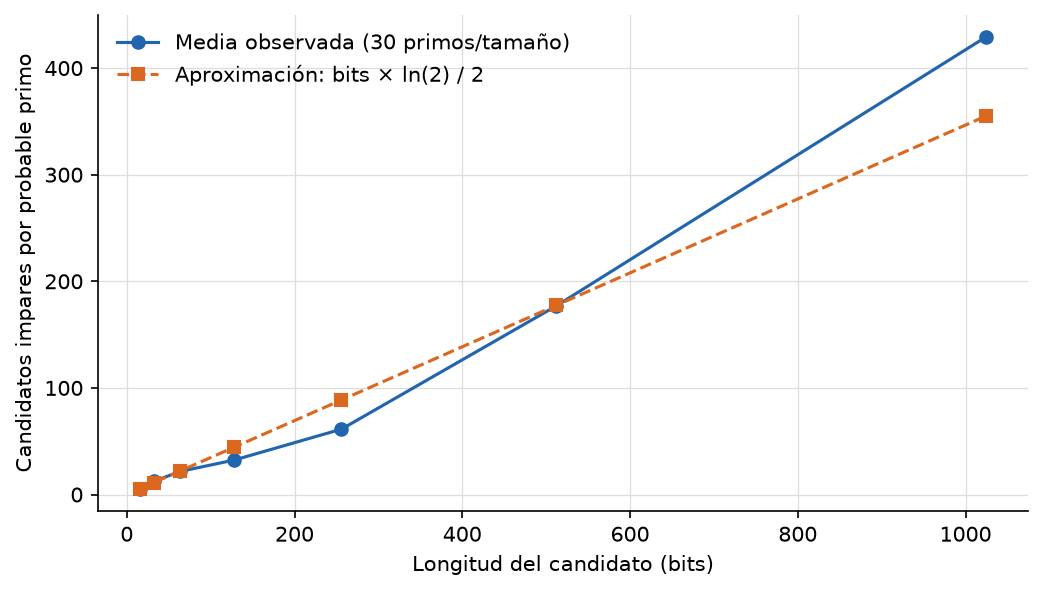

In [27]:
exp.plot_candidates(generation)
display(Image(filename='figures/fig3_candidatos_vs_bits.png'))

### Comparación: Fermat, Miller–Rabin y división de prueba
Se muestran los tiempos medianos por método y una muestra con mínimo, mediana, máximo, rondas y cuadrados.

In [28]:
comparison_rows, comparison = exp.compare_methods(primes_by_bits)
display(pd.DataFrame(comparison).query("tipo_entrada != 'compuesto_construido'").pivot(index='bits', columns=['metodo', 'rondas'], values='tiempo_mediano_us'))
display(pd.DataFrame(comparison_rows).query("bits == 16 and indice == 0 and tipo_entrada == 'primo_verificado'")[['metodo', 'rondas_solicitadas', 'rondas_ejecutadas', 'cuadrados_modulares', 'min_ns', 'mediana_ns', 'max_ns', 'resultado']])

Comparación   16 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas) y división
Comparación   32 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas) y división
Comparación   64 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación  128 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación  256 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación  512 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación 1024 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)


metodo    fermat                                 miller_rabin            \
rondas        1         5          10         20           1         5    
bits                                                                      
16          8.40     36.30      71.20     113.20        11.85     46.85   
32         30.25    127.15     292.60     599.50        32.40    158.70   
64         69.35    363.00     707.55    1452.25        74.45    376.85   
128       190.05    931.15    1862.35    3740.10       157.10    932.85   
256       531.60   2653.25    4362.40   10240.60       536.80   2699.10   
512      2030.40  10739.55   21287.45   43146.15      2229.75  10767.10   
1024    11407.85  57377.65  114852.85  226377.35     11342.05  56768.40   

metodo                       division_prueba  
rondas         10         20              0   
bits                                          
16          91.45     137.80           12.95  
32         313.00     613.20         4631.70  
64         710.40    1412.75             NaN  
128       1828.75    3493.15             NaN  
256       5043.15    9479.35             NaN  
512      22457.05   43462.40             NaN  
1024    114017.55  229585.40             NaN

,metodo,rondas_solicitadas,rondas_ejecutadas,cuadrados_modulares,min_ns,mediana_ns,max_ns,resultado
0,fermat,1,1,15,9700,10400,18700,pasa_fermat
1,fermat,5,5,75,45800,46300,49400,pasa_fermat
2,fermat,10,10,150,88700,89300,101500,pasa_fermat
3,fermat,20,20,300,175900,177100,179800,pasa_fermat
4,miller_rabin,1,1,14,14400,14700,20500,probable_primo
5,miller_rabin,5,5,70,58100,59400,129100,probable_primo
6,miller_rabin,10,10,140,82600,115400,252600,probable_primo
7,miller_rabin,20,20,280,127400,133400,184200,probable_primo
8,division_prueba,0,0,0,10200,10400,11800,primo


### Figura 1: tiempo por longitud binaria

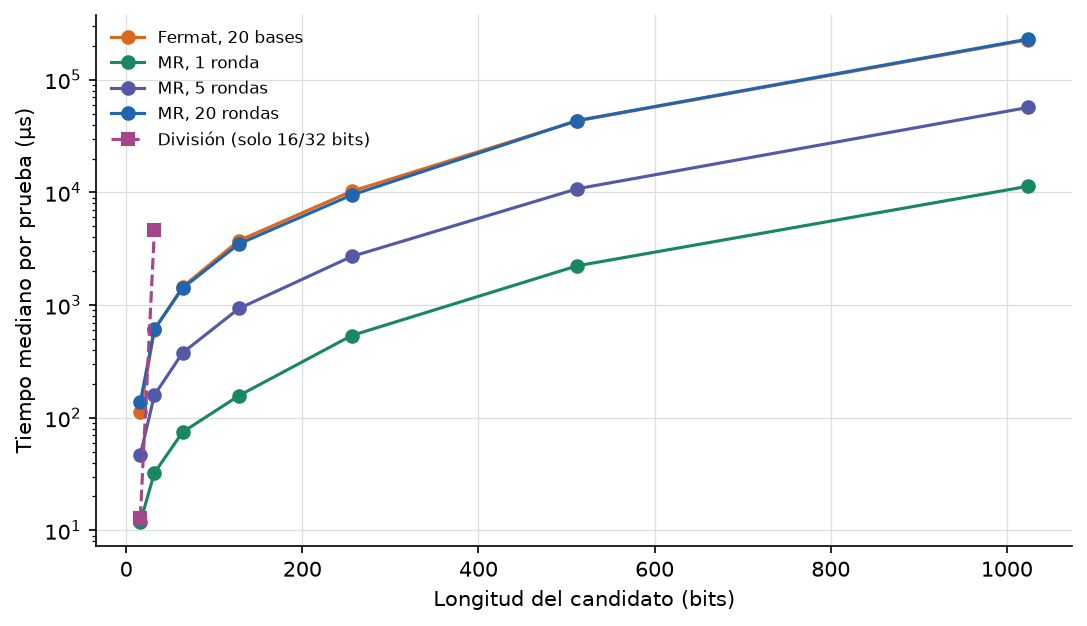

In [29]:
exp.plot_timing(comparison)
display(Image(filename='figures/fig1_tiempo_vs_bits.png'))

### Figura 2: cuadrados modulares y rondas

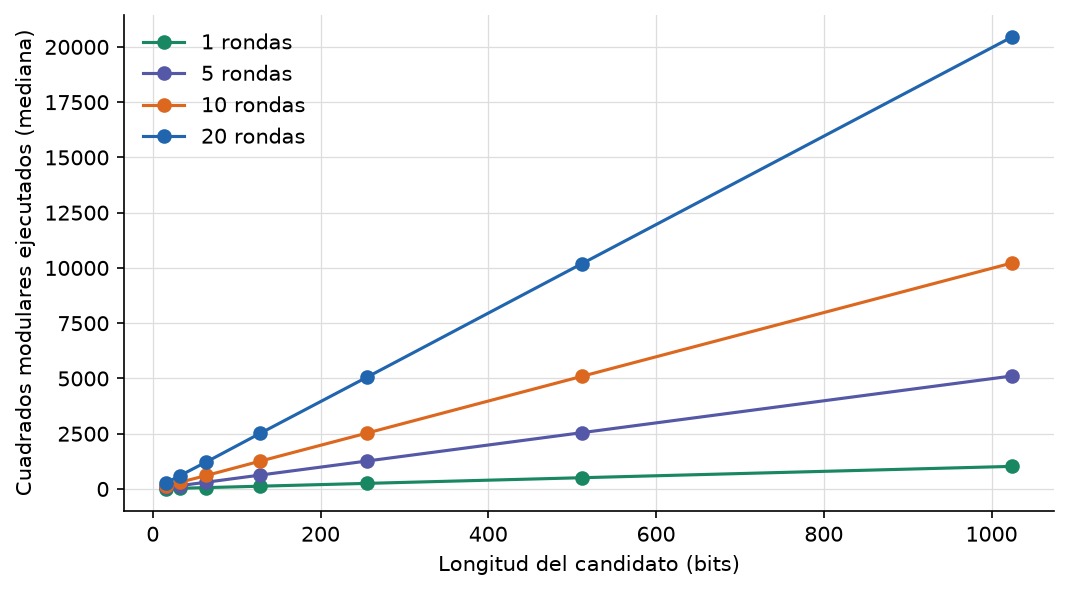

In [30]:
exp.plot_squares(comparison)
display(Image(filename='figures/fig2_cuadrados_vs_bits.png'))

### Testigos, mentirosos fuertes y frecuencia de error
La tasa empírica se compara con la tasa exacta para cada compuesto y la cota teórica universal.

In [31]:
liars, rates = exp.liars_and_error()
display(pd.DataFrame(liars).query('n in [25, 91, 121, 221, 341, 561]'))
display(pd.DataFrame(rates).query('n == 25'))

,n,bases_validas,testigos,mentirosos_fuertes,fraccion_mentirosos,cota_un_cuarto
3,25,22,20,2,0.090909,0.25
21,91,88,72,16,0.181818,0.25
30,121,118,110,8,0.067797,0.25
54,221,218,214,4,0.018349,0.25
55,341,338,290,48,0.142012,0.25
56,561,558,550,8,0.014337,0.25


,seed,n,rondas,muestras,compuestos_aceptados,tasa_empirica,tasa_exacta_bases_aleatorias,cota_teorica
0,20260703,25,1,3000,281,0.093667,9.090909e-02,2.500000e-01
1,20260703,25,5,3000,0,0.000000,6.209213e-06,9.765625e-04
2,20260703,25,10,3000,0,0.000000,3.855433e-11,9.536743e-07
3,20260703,25,20,3000,0,0.000000,1.486436e-21,9.094947e-13


### Figura 4: errores observados y cota teórica
`0/3000` indica cero aceptaciones observadas, no probabilidad nula.

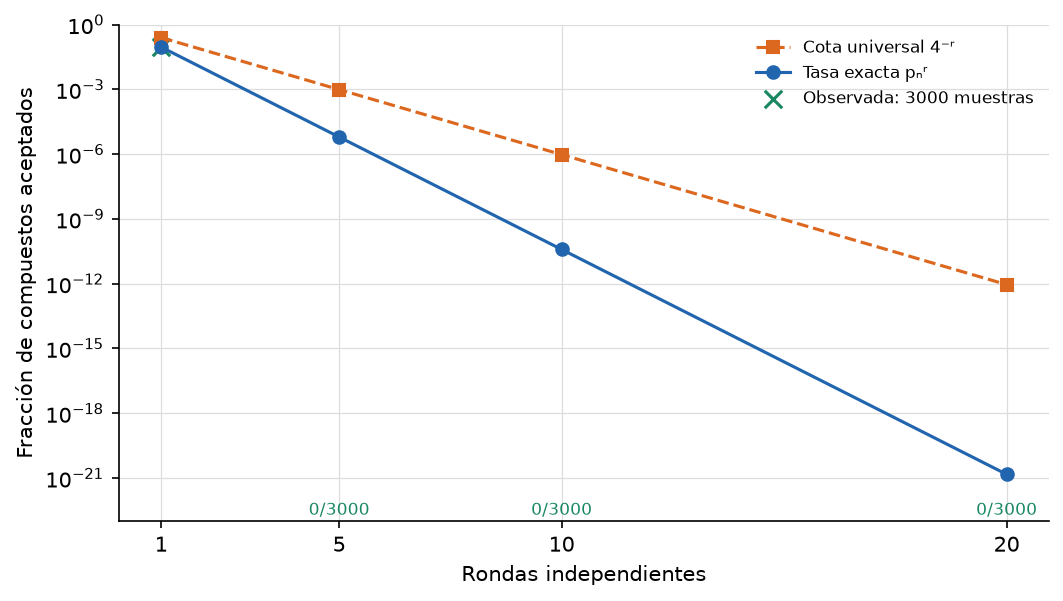

In [32]:
exp.plot_error(rates)
display(Image(filename='figures/fig4_error_empirico.png'))

### Tablas para el informe y auditoría de los archivos generados

In [33]:
exp.latex_tables(generation, comparison, rates, liars, comparison_rows)
print('Tablas LaTeX:', ', '.join(sorted(p.name for p in exp.LATEX.glob('*.tex'))))

Tablas LaTeX: 04_analisis_costo.tex, 04_analisis_generacion.tex, 04_tab_dispersion.tex, 04_tab_error.tex, 04_tab_generacion.tex, 04_tab_mentirosos.tex, 04_tab_tiempos.tex


In [34]:
%%writefile verify_results.py
"""Comprueba que los archivos generados satisfacen los mínimos de la Guía 07.

Ejecutar después de experiments.py: python python/verify_results.py
No reemplaza la suite unittest ni prueba primalidad de los números grandes.
"""

import csv
import json
from collections import Counter
from pathlib import Path

BASE = Path(__file__).resolve().parent
DATA = BASE / "results"
SIZES = (16, 32, 64, 128, 256, 512, 1024)


def rows(filename):
    with (DATA / filename).open(newline="", encoding="utf-8") as file:
        return list(csv.DictReader(file))


def verify():
    known = {int(row["n"]): row for row in rows("casos_conocidos.csv")}
    assert {0, 1, 2, 3, 221, 341, 561, 1105, 1729} <= known.keys()
    assert all(known[n]["clasificacion"] == "no_primo_ni_compuesto" for n in (0, 1))
    assert all(known[n]["fermat_base_2"] == "True" and
               known[n]["miller_rabin_base_2"] == "False"
               for n in (341, 561, 1105, 1729))

    traces = {(int(r["n"]), int(r["a"])): r
              for r in rows("trazas_miller_rabin.csv")}
    for n, residues in ((221, [128, 30]), (341, [32, 1]),
                        (561, [263, 166, 67, 1])):
        assert json.loads(traces[n, 2]["residuos"]) == residues

    generated = rows("generacion_210_probables_primos.csv")
    counts = Counter(int(r["bits"]) for r in generated)
    assert counts == Counter({bits: 30 for bits in SIZES})
    for row in generated:
        bits, n = int(row["bits"]), int(row["n"])
        assert n.bit_length() == bits and n % 2 == 1
        assert int(row["candidatos"]) > 0
        assert row["resultado"] == ("primo_verificado" if bits <= 32 else "probable_primo")
        assert int(row["descartes_precribado"]) < int(row["candidatos"])
        assert int(row["rondas_finales"]) == 20

    generation_summary = rows("resumen_generacion.csv")
    assert {int(r["bits"]) for r in generation_summary} == set(SIZES)
    for r in generation_summary:
        assert int(r["candidatos_total"]) == sum(int(g["candidatos"]) for g in generated
                                                  if g["bits"] == r["bits"])
        assert float(r["tiempo_min_ms"]) <= float(r["tiempo_mediano_ms"]) <= float(r["tiempo_max_ms"])

    inputs = rows("entradas_y_bases.csv")
    assert len(inputs) == 7 * 2 * 8
    for r in inputs:
        bases = json.loads(r["bases_20"])
        n = int(r["n"])
        assert len(bases) == 20 and all(2 <= a <= n - 2 for a in bases)

    comparison = rows("comparacion_metodos.csv")
    assert len(comparison) == 928
    assert {int(r["bits"]) for r in comparison} == set(SIZES)
    assert {int(r["rondas_solicitadas"]) for r in comparison} == {0, 1, 5, 10, 20}
    for r in comparison:
        assert int(r["min_ns"]) <= float(r["mediana_ns"]) <= int(r["max_ns"])
        if r["metodo"] == "division_prueba":
            assert int(r["bits"]) <= 32

    summary = rows("resumen_testigos_mentirosos.csv")
    classifications = rows("clasificacion_bases.csv")
    assert {221, 341, 561} <= {int(r["n"]) for r in summary}
    assert len(classifications) == sum(int(r["bases_validas"]) for r in summary)
    for r in summary:
        assert int(r["bases_validas"]) == int(r["testigos"]) + int(r["mentirosos_fuertes"])
        assert int(r["mentirosos_fuertes"]) / int(r["bases_validas"]) <= 0.25

    rates = rows("tasa_error_empirica.csv")
    assert len(rates) == 5 * 4
    for r in rates:
        assert int(r["muestras"]) == 3000
        assert float(r["cota_teorica"]) == 4.0 ** (-int(r["rondas"]))
        assert 0 <= float(r["tasa_exacta_bases_aleatorias"]) <= float(r["cota_teorica"])
    assert next(float(r["tasa_exacta_bases_aleatorias"]) for r in rates
                if r["n"] == "25" and r["rondas"] == "20") > 0

    figures = list((BASE / "figures").glob("fig*.png"))
    assert len(figures) >= 4 and all(f.stat().st_size > 1000 for f in figures)
    latex_dir = (BASE.parent / "latex" / "secciones" if BASE.name == "python"
                 else BASE / "latex_tables")
    fragments = ("04_tab_generacion.tex", "04_tab_tiempos.tex",
                 "04_tab_dispersion.tex", "04_tab_mentirosos.tex",
                 "04_tab_error.tex", "04_analisis_generacion.tex",
                 "04_analisis_costo.tex")
    assert all((latex_dir / name).is_file() and (latex_dir / name).stat().st_size > 100
               for name in fragments)
    print(f"Evidencias válidas: {len(generated)} probables primos, "
          f"{len(comparison)} comparaciones, {len(classifications)} bases, "
          f"{len(figures)} gráficos.")


if __name__ == "__main__":
    verify()


Writing verify_results.py


In [35]:
import verify_results
verify_results.verify()

Evidencias válidas: 210 probables primos, 928 comparaciones, 6726 bases, 4 gráficos.


## 12. Análisis (respuestas breves)
1. Todo compuesto $n=ab$ tiene un factor $\leq\sqrt n$: si ambos fueran mayores, su producto excedería $n$.
2. En $L$ bits, $\sqrt n=\Theta(2^{L/2})$, exponencial en $L$.
3. Si Fermat falla, $n$ es compuesto; si pasa, $n$ puede ser pseudoprimo.
4. Un pseudoprimo pasa una base coprima; Carmichael pasa todas las coprimas.
5. La descomposición $n-1=2^sd$ permite buscar $-1$ en la cadena de cuadrados.
6. Una raíz no trivial de $1$ módulo $n$ implica composición.
7. Testigo: rechaza un compuesto; mentiroso fuerte: lo acepta.
8. Un primo nunca es rechazado por una base válida: error unilateral.
9. $4^{-r}$ requiere bases uniformes independientes para compuesto impar.
10. Una semilla fija permite reconstruir claves; para ellas, usar fuente segura.
11. El precribado elimina factores pequeños antes de rondas costosas.
12. Cero errores en una muestra finita no prueba probabilidad cero.

## 13. Archivos de entrega
El PDF del informe se compila por separado en `latex/main.pdf`. Aquí se empaquetan código, diez CSV, cuatro figuras y los fragmentos LaTeX. En Colab se descarga automáticamente; en Jupyter aparece un enlace de descarga directamente en esta celda, sin buscar rutas temporales. El cuaderno conserva sus resultados incrustados.

In [36]:
from zipfile import ZIP_DEFLATED, ZipFile
archive = WORK / 'lab07_resultados.zip'
with ZipFile(archive, 'w', ZIP_DEFLATED) as zf:
    for folder in ('results', 'figures', 'latex_tables'):
        for path in sorted(Path(folder).glob('*')):
            if path.is_file():
                zf.write(path)
    for name in ('primality.py', 'case_generator.py', 'experiments.py', 'test_primality.py', 'ejercicios_resueltos.py', 'verify_results.py'):
        zf.write(name)
print('Archivo preparado: lab07_resultados.zip')
try:
    from google.colab import files
except ImportError:
    from base64 import b64encode
    from IPython.display import HTML
    encoded = b64encode(archive.read_bytes()).decode('ascii')
    display(HTML('<a download="lab07_resultados.zip" ''href="data:application/zip;base64,' + encoded + '">Descargar resultados (ZIP)</a>'))
else:
    files.download(str(archive))

Archivo preparado: lab07_resultados.zip
